In [1]:
from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"

ATTR_PATHS = {
    "ig_text":        Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_attributions.npz"),
    "ig_tokens":      Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_tokens.json"),
    "cross_attn":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a2-cross-attn/xai_2A2_cross_attention/cross_attn_maps.npz"),
    "rollout":        Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a3-rollout/xai_2A3_attention_rollout/rollout_maps.npz"),
    "incongruity":    Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a4-incongruity/xai_2A4_incongruity_heatmap/incongruity_maps.npz"),
}

OUTPUT_DIR = Path("/kaggle/working/xai_2C_case_studies")
FIG_DIR    = OUTPUT_DIR / "figures"
for d in [OUTPUT_DIR, FIG_DIR]: d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id        = "2C_case_studies",
    seed          = 42,
    img_size      = 224,
    grid_size     = 14,
    n_samples_total = 10,                 # total case studies
    samples_per_category = {"TP": 3, "TN": 3, "FP": 2, "FN": 2},
)
print(f"Output: {OUTPUT_DIR}")

Output: /kaggle/working/xai_2C_case_studies


In [2]:
import os, json, random, re, unicodedata, math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.patches import Rectangle
from sklearn.metrics import confusion_matrix, classification_report

random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])
print("OK")

OK


In [3]:
"""
NOTEBOOK 2C - Visualisasi & Studi Kasus (Fase 2C)
IndoMeme-XAI

Generate:
  - 10 case study figures (sample x [original + 4 XAI methods])
  - Per-topic aggregate analysis
  - Error case deep dive (FP, FN)
  - Confusion matrix + per-class metrics
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"

ATTR_PATHS = {
    "ig_text":        Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_attributions.npz"),
    "ig_tokens":      Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_tokens.json"),
    "cross_attn":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a2-cross-attn/xai_2A2_cross_attention/cross_attn_maps.npz"),
    "rollout":        Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a3-rollout/xai_2A3_attention_rollout/rollout_maps.npz"),
    "incongruity":    Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a4-incongruity/xai_2A4_incongruity_heatmap/incongruity_maps.npz"),
}

OUTPUT_DIR = Path("/kaggle/working/xai_2C_case_studies")
FIG_DIR    = OUTPUT_DIR / "figures"
for d in [OUTPUT_DIR, FIG_DIR]: d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id        = "2C_case_studies",
    seed          = 42,
    img_size      = 224,
    grid_size     = 14,
    n_samples_total = 10,                 # total case studies
    samples_per_category = {"TP": 3, "TN": 3, "FP": 2, "FN": 2},
)
print(f"Output: {OUTPUT_DIR}")

Output: /kaggle/working/xai_2C_case_studies


In [4]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu","aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak","ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak","engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena","krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi","klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau","spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget","bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang","skrg":"sekarang","skrng":"sekarang","td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana","gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah","blm":"belum","blom":"belum","lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih","jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu","liat":"lihat","ngeliat":"melihat","denger":"dengar","ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja","sih":"","deh":"","dong":"","kok":"","lah":"","loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya","org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada","thd":"terhadap","ttg":"tentang","abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman","rmh":"rumah","kntr":"kantor","krj":"kerja","ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha","hahaha":"haha","hahahaha":"haha","hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing","anjr":"anjing","anying":"anjing","njir":"anjing","bgsd":"bangsat","bgst":"bangsat","bjir":"anjing","bjg":"bajingan","kntl":"kontol","mmk":"memek","tai":"tahi",
}
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+"); HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE); MULTI_SPACE = re.compile(r"\s+")
SEP_TOKEN = "[SEP]"
def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)
def _normalize_slang(text):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{SLANG_DICT.get(core.lower(), core)}{suffix}")
    return " ".join(out)
def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()
def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

In [5]:
df = pd.read_csv(CSV_PATH)
df["label"] = df["hate_final"].map({"not hate": 0, "hate": 1})
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)
df_test = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Test samples: {len(df_test)}")
print(df_test["topic"].value_counts().head(8))

Test samples: 1005
topic
social sub-groups              445
gender                         111
individual, political           51
institutions                    49
political                       39
individual                      37
national origin                 36
social sub-groups, religion     17
Name: count, dtype: int64


In [6]:
attr = {}

# IG (text)
ig_data = np.load(ATTR_PATHS["ig_text"])
attr["ig_text"] = {
    "token_l2":   ig_data["token_l2"],
    "token_sum":  ig_data["token_sum"],
    "att_mask":   ig_data["attention_mask"],
    "idxs":       ig_data["idxs"],
    "pred":       ig_data["pred_class"],
    "true":       ig_data["true_label"],
    "prob":       ig_data["pred_prob"],
}
with open(ATTR_PATHS["ig_tokens"]) as f:
    ig_tokens_list = json.load(f)
attr["ig_text"]["tokens"] = {item["idx"]: item["tokens"] for item in ig_tokens_list}

# Image methods
for name, key in [("cross_attn", "maps_14x14"), ("rollout", "maps_14x14"),
                   ("incongruity", "maps_softmax_14x14")]:
    d = np.load(ATTR_PATHS[name])
    attr[name] = {
        "maps":  d[key],
        "idxs":  d["idxs"],
        "pred":  d["pred_class"],
        "true":  d["true_label"],
        "prob":  d["pred_prob"],
    }

# Verify alignment
ref = attr["ig_text"]["idxs"]
for name in ["cross_attn", "rollout", "incongruity"]:
    assert np.array_equal(ref, attr[name]["idxs"]), f"idx mismatch {name}"

print(f"Loaded attribution dari 4 metode untuk {len(ref)} sampel test.")

Loaded attribution dari 4 metode untuk 1005 sampel test.


In [7]:
def overlay_attn(img_pil, attn_14x14, alpha=0.5, cmap_name="jet"):
    H = W = CONFIG["img_size"]
    attn_t = torch.from_numpy(attn_14x14).float().unsqueeze(0).unsqueeze(0)
    attn_up = F.interpolate(attn_t, size=(H, W), mode="bilinear", align_corners=False)
    attn_np = attn_up.squeeze().numpy()
    a_min, a_max = attn_np.min(), attn_np.max()
    attn_norm = (attn_np - a_min) / (a_max - a_min + 1e-8)
    cmap = cm.get_cmap(cmap_name)
    heat = cmap(attn_norm)[..., :3]
    img_arr = np.asarray(img_pil.resize((W, H))).astype(np.float32) / 255.0
    if img_arr.ndim == 2: img_arr = np.stack([img_arr]*3, axis=-1)
    if img_arr.shape[-1] == 4: img_arr = img_arr[..., :3]
    return np.clip((1-alpha) * img_arr + alpha * heat, 0, 1)


def render_text_attribution(ax, tokens, scores, mask, max_show=60, title="IG Text Attribution"):
    """Color tokens by IG L2 score using matplotlib text+bbox."""
    SPECIAL = {"[CLS]", "[SEP]", "[PAD]", "[UNK]"}
    real = [(t, s) for t, s, m in zip(tokens, scores, mask) if m and t not in SPECIAL][:max_show]
    if not real:
        ax.set_title(title, fontsize=11); ax.axis("off"); return

    rs = np.array([s for _, s in real])
    s_min, s_max = rs.min(), rs.max()
    norm_lin = (rs - s_min) / (s_max - s_min + 1e-8)
    norm = np.power(norm_lin, 0.5)  # sqrt power-law: kontras lebih tajam

    cmap = plt.cm.Reds
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    n = len(real)
    cols = 8  # lebih sedikit kolom -> token lebih lebar & terbaca
    rows = math.ceil(n / cols)
    cell_w = 1.0 / cols
    cell_h = 0.88 / max(rows, 1)

    for i, ((tok, sc), nrm) in enumerate(zip(real, norm)):
        r, c = i // cols, i % cols
        x = c * cell_w + cell_w * 0.5
        y = 0.94 - (r + 0.5) * cell_h
        color = cmap(0.05 + 0.95 * float(nrm))  # full range 0.05-1.0
        lum = 0.299*color[0] + 0.587*color[1] + 0.114*color[2]
        txt_color = "white" if lum < 0.45 else "black"
        ax.text(x, y, tok,
                fontsize=10, ha="center", va="center",
                family="monospace", color=txt_color, fontweight="bold",
                bbox=dict(facecolor=color, edgecolor="none",
                          pad=3.5, boxstyle="round,pad=0.3"))
    ax.set_title(title, fontsize=11, fontweight="bold", pad=6)

In [8]:
preds = attr["ig_text"]["pred"]
trues = attr["ig_text"]["true"]
idxs  = attr["ig_text"]["idxs"]

# Build combined dataframe utk seleksi
df_meta = pd.DataFrame({
    "idx":   idxs,
    "pred":  preds,
    "true":  trues,
    "prob":  attr["ig_text"]["prob"],
})
df_meta = df_meta.merge(
    df_test[["idx","topic","text_input","full_image_path","ocr","caption"]],
    on="idx", how="left"
)
df_meta["category"] = df_meta.apply(
    lambda r: ("TP" if r["pred"] == 1 and r["true"] == 1 else
               "TN" if r["pred"] == 0 and r["true"] == 0 else
               "FP" if r["pred"] == 1 and r["true"] == 0 else "FN"), axis=1
)

print("Distribusi outcome di test:")
print(df_meta["category"].value_counts())

# Pilih sampel per kategori dengan diversitas topik
def select_diverse(df_subset, n, primary_topics_priority=None, seed=42):
    """Pilih n sampel berbeda topik, prioritaskan topik populer."""
    rng = np.random.RandomState(seed)
    if primary_topics_priority is None:
        primary_topics_priority = df_subset["topic"].value_counts().index.tolist()
    selected = []
    used_topics = set()
    for topic in primary_topics_priority:
        if len(selected) >= n: break
        candidates = df_subset[df_subset["topic"] == topic]
        if len(candidates) == 0: continue
        # Pilih sampel dengan pred_prob menengah (lebih informatif daripada extreme)
        candidates = candidates.sort_values("prob", ascending=False)
        if topic in used_topics: continue
        # Pilih random dari kandidat
        chosen = candidates.sample(1, random_state=int(rng.randint(0, 1e6))).iloc[0]
        selected.append(chosen)
        used_topics.add(topic)
    # Fill remaining slots randomly if needed
    while len(selected) < n:
        remaining = df_subset[~df_subset["idx"].isin([s["idx"] for s in selected])]
        if len(remaining) == 0: break
        chosen = remaining.sample(1, random_state=int(rng.randint(0, 1e6))).iloc[0]
        selected.append(chosen)
    return selected

selected_samples = []
for cat, n in CONFIG["samples_per_category"].items():
    df_cat = df_meta[df_meta["category"] == cat]
    if len(df_cat) == 0: continue
    picks = select_diverse(df_cat, n, seed=hash(cat) % 10000)
    for p in picks:
        selected_samples.append(p)

print(f"\nTotal selected: {len(selected_samples)}")
for s in selected_samples:
    print(f"  {s['category']:3s} idx={s['idx']:4d} topic={str(s['topic']):30s} pred={s['pred']} ({s['prob']:.0%}) true={s['true']}")

Distribusi outcome di test:
category
TN    560
TP    259
FP     98
FN     88
Name: count, dtype: int64

Total selected: 10
  TP  idx= 173 topic=social sub-groups              pred=1 (87%) true=1
  TP  idx= 292 topic=individual, political          pred=1 (78%) true=1
  TP  idx= 856 topic=political                      pred=1 (89%) true=1
  TN  idx= 932 topic=social sub-groups              pred=0 (87%) true=0
  TN  idx= 139 topic=gender                         pred=0 (71%) true=0
  TN  idx= 476 topic=social sub-groups, religion    pred=0 (96%) true=0
  FP  idx=  55 topic=gender                         pred=1 (60%) true=0
  FP  idx= 976 topic=social sub-groups              pred=1 (59%) true=0
  FN  idx= 284 topic=social sub-groups              pred=0 (80%) true=1
  FN  idx= 146 topic=gender                         pred=0 (54%) true=1


In [9]:
def get_idx_position(target_idx):
    """Cari row position dari target_idx di global idxs array."""
    return int(np.where(attr["ig_text"]["idxs"] == target_idx)[0][0])

def make_case_study_figure(sample_row, save_path):
    pos = get_idx_position(sample_row["idx"])

    fig = plt.figure(figsize=(22, 11))
    gs = fig.add_gridspec(2, 4, height_ratios=[3, 2.2], hspace=0.35, wspace=0.10)

    img = Image.open(sample_row["full_image_path"]).convert("RGB")
    ax_orig = fig.add_subplot(gs[0, 0])
    ax_orig.imshow(img.resize((CONFIG["img_size"], CONFIG["img_size"])))
    ax_orig.set_title(f"Original\nidx={sample_row['idx']}", fontsize=10)
    ax_orig.axis("off")

    image_methods = [
        ("Cross-Attn",  attr["cross_attn"]["maps"][pos]),
        ("Rollout",     attr["rollout"]["maps"][pos]),
        ("Incongruity", attr["incongruity"]["maps"][pos]),
    ]
    for i, (name, m) in enumerate(image_methods):
        ax = fig.add_subplot(gs[0, i+1])
        ax.imshow(overlay_attn(img, m, alpha=0.5))
        ax.set_title(name, fontsize=10)
        ax.axis("off")

    # IG row: penuh + lebih tinggi
    ax_text = fig.add_subplot(gs[1, :])
    tokens   = attr["ig_text"]["tokens"][int(sample_row["idx"])]
    scores   = attr["ig_text"]["token_l2"][pos]
    att_mask = attr["ig_text"]["att_mask"][pos]
    render_text_attribution(ax_text, tokens, scores, att_mask,
                            title="Integrated Gradients (Text)")

    # Colorbar legend
    from matplotlib.colorbar import ColorbarBase
    from matplotlib.colors import Normalize
    cax = fig.add_axes([0.92, 0.06, 0.012, 0.28])
    cb = ColorbarBase(cax, cmap=plt.cm.Reds,
                      norm=Normalize(vmin=0, vmax=1),
                      orientation="vertical")
    cb.set_label("Attribution (norm)", fontsize=8)
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(["low", "mid", "high"])

    pred_str = "hate" if sample_row["pred"] == 1 else "not_hate"
    true_str = "hate" if sample_row["true"] == 1 else "not_hate"
    fig.suptitle(
        f"[{sample_row['category']}] pred={pred_str} ({sample_row['prob']:.0%})  |  true={true_str}  |  topic={sample_row['topic']}",
        fontsize=13, fontweight="bold", y=1.01
    )
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)


print("Generating case study figures...")
for i, s in enumerate(selected_samples):
    topic_slug = re.sub(r"[^\w]+", "_", str(s["topic"]))[:30]
    fname = f"case_{i+1:02d}_{s['category']}_idx{s['idx']}_{topic_slug}.png"
    make_case_study_figure(s, FIG_DIR / fname)
    print(f"  saved: {fname}")

print(f"\n{len(selected_samples)} case study figures saved to {FIG_DIR}")


Generating case study figures...


/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


  saved: case_01_TP_idx173_social_sub_groups.png


/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


  saved: case_02_TP_idx292_individual_political.png


/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


... (11 outputs left out)

/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


  saved: case_09_FN_idx284_social_sub_groups.png


/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


  saved: case_10_FN_idx146_gender.png

10 case study figures saved to /kaggle/working/xai_2C_case_studies/figures


/tmp/ipykernel_22/3574566672.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


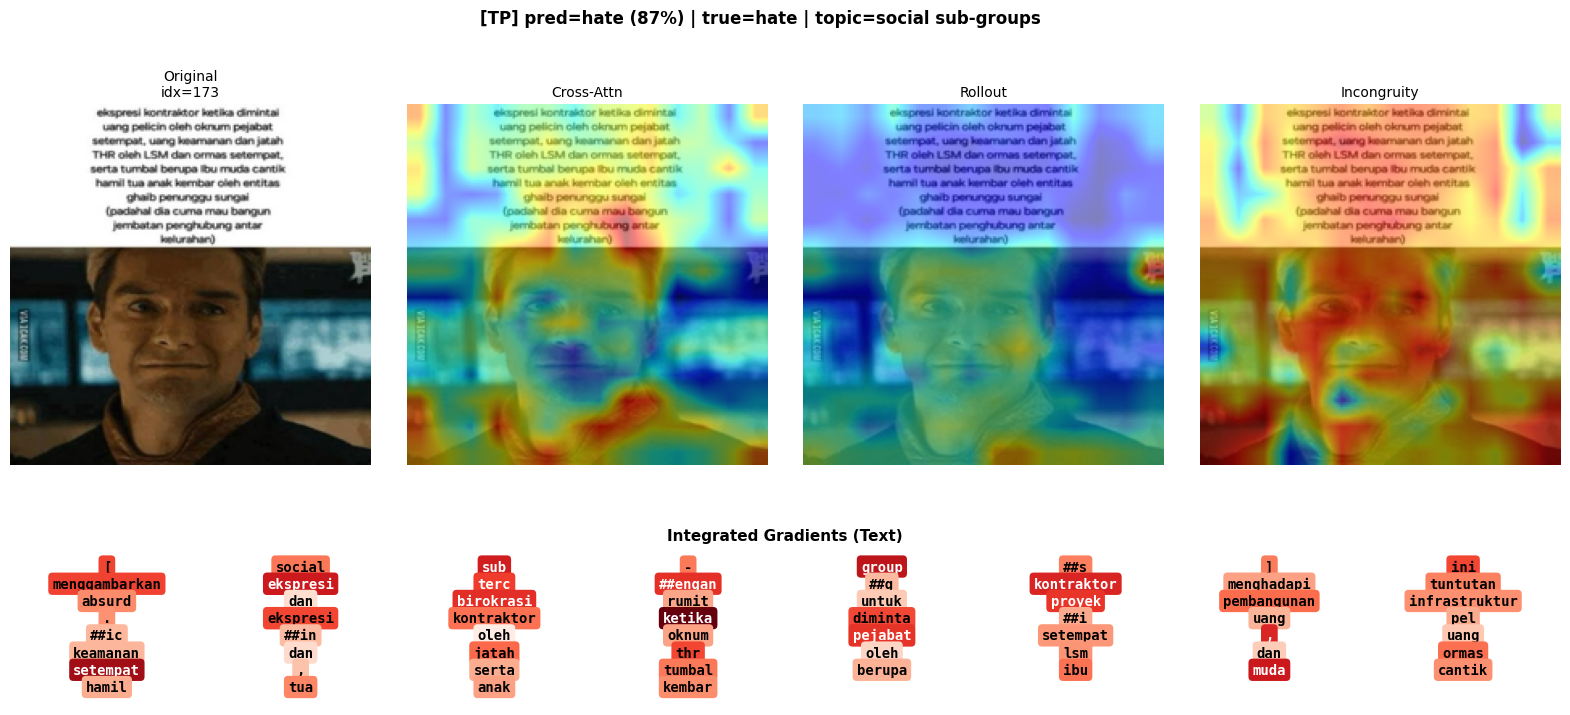

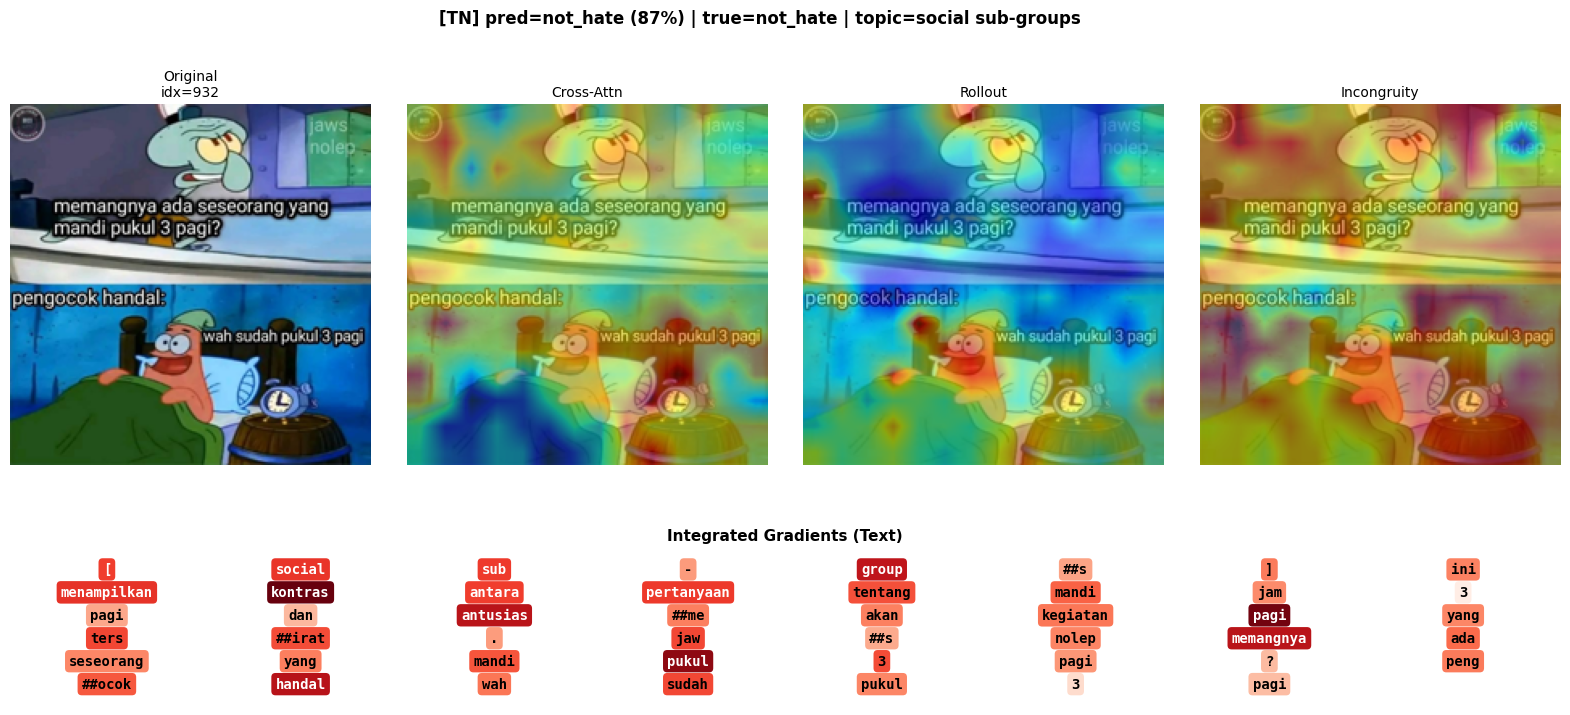

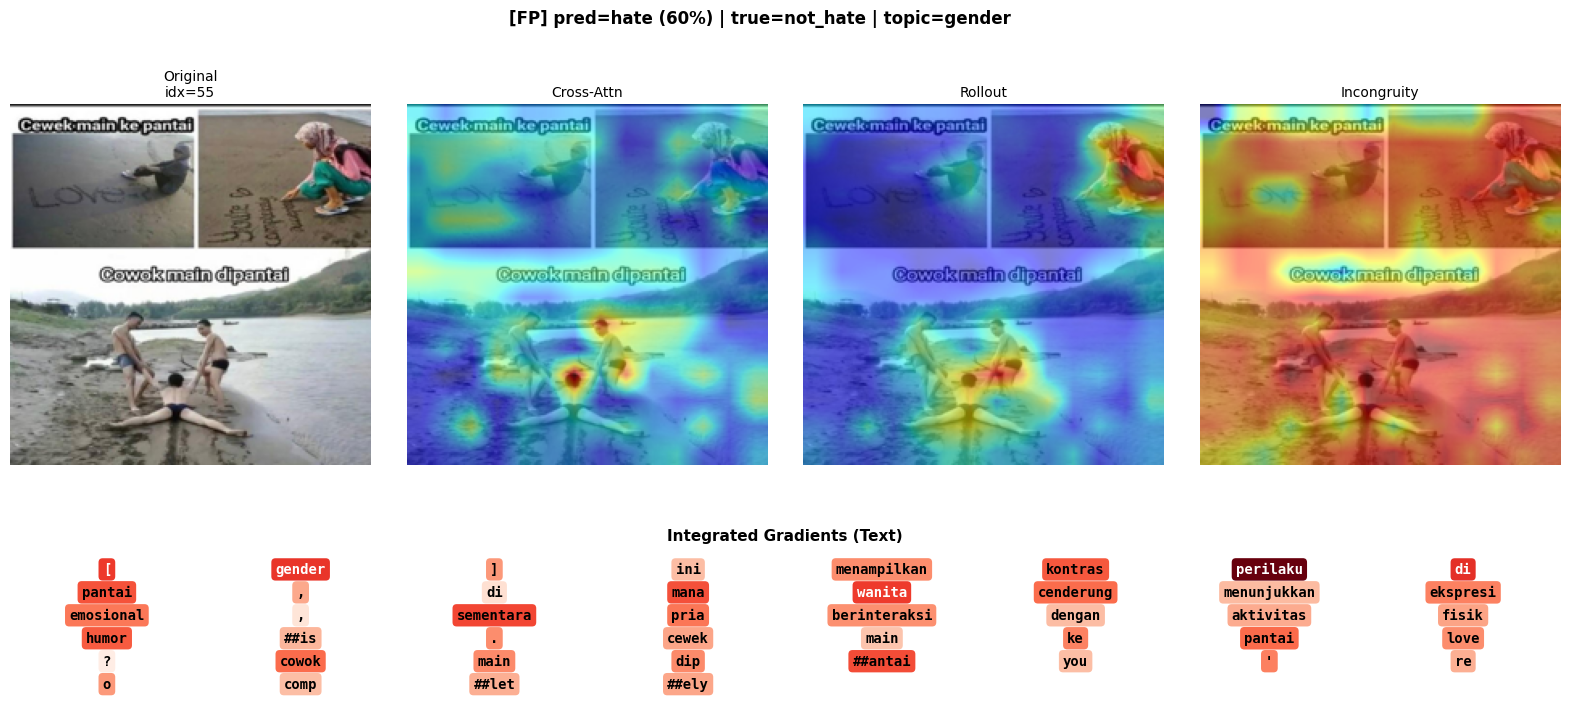

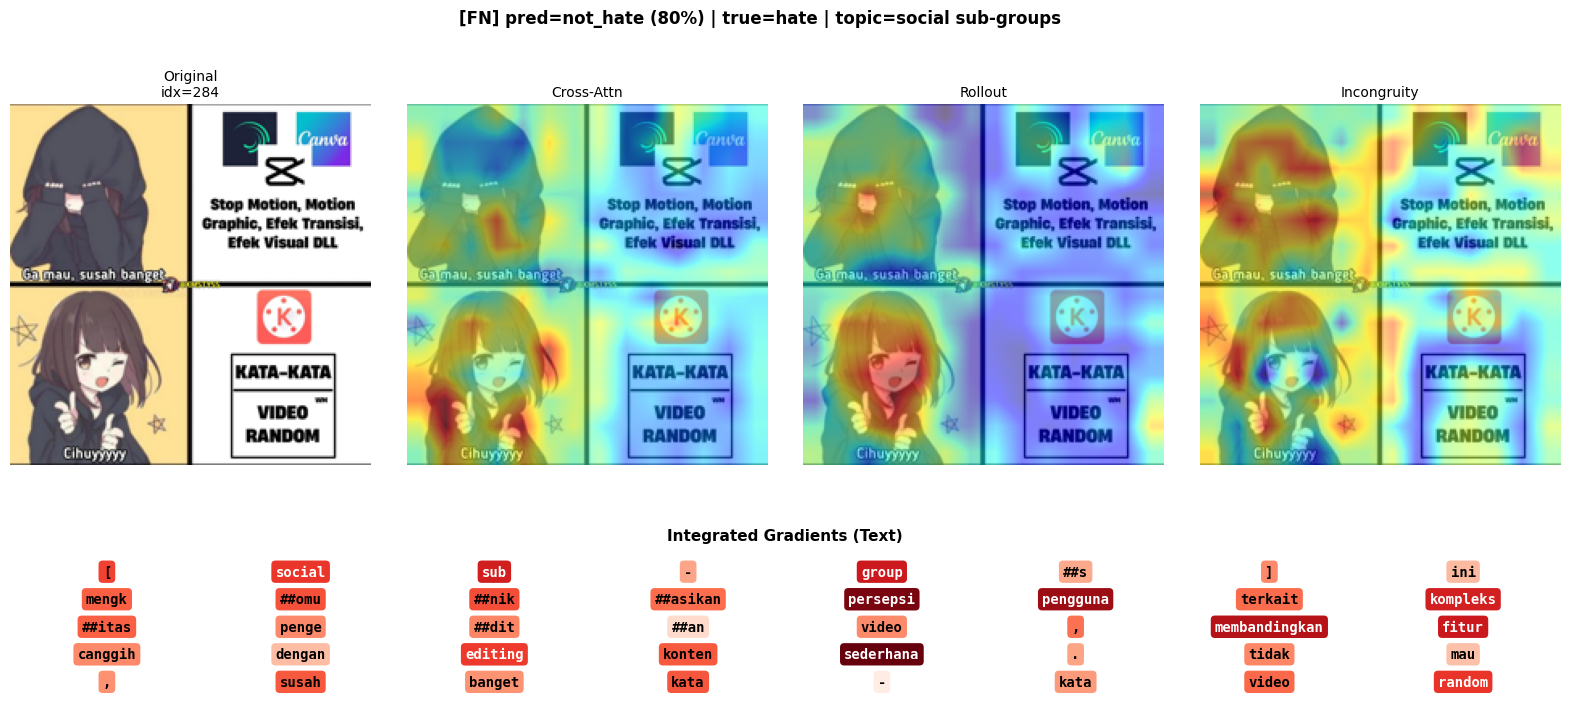

In [10]:
# Tampilkan 4 case study utama (1 per kategori) untuk preview
display_picks = []
seen_cats = set()
for s in selected_samples:
    if s["category"] not in seen_cats:
        display_picks.append(s)
        seen_cats.add(s["category"])

for s in display_picks:
    pos = get_idx_position(s["idx"])
    img = Image.open(s["full_image_path"]).convert("RGB")
    fig = plt.figure(figsize=(20, 8))
    gs = fig.add_gridspec(2, 4, height_ratios=[3, 1.2], hspace=0.25, wspace=0.10)
    ax = fig.add_subplot(gs[0, 0])
    ax.imshow(img.resize((CONFIG["img_size"], CONFIG["img_size"]))); ax.axis("off")
    ax.set_title(f"Original\nidx={s['idx']}", fontsize=10)
    for i, (name, key) in enumerate([("Cross-Attn", "cross_attn"), ("Rollout", "rollout"), ("Incongruity", "incongruity")]):
        ax = fig.add_subplot(gs[0, i+1])
        ax.imshow(overlay_attn(img, attr[key]["maps"][pos], alpha=0.5))
        ax.set_title(name, fontsize=10); ax.axis("off")
    ax_t = fig.add_subplot(gs[1, :])
    render_text_attribution(ax_t,
        attr["ig_text"]["tokens"][int(s["idx"])],
        attr["ig_text"]["token_l2"][pos],
        attr["ig_text"]["att_mask"][pos],
        title="Integrated Gradients (Text)")
    pred_str = "hate" if s["pred"] == 1 else "not_hate"
    true_str = "hate" if s["true"] == 1 else "not_hate"
    fig.suptitle(f"[{s['category']}] pred={pred_str} ({s['prob']:.0%}) | true={true_str} | topic={s['topic']}",
                 fontsize=12, fontweight="bold")
    plt.show()

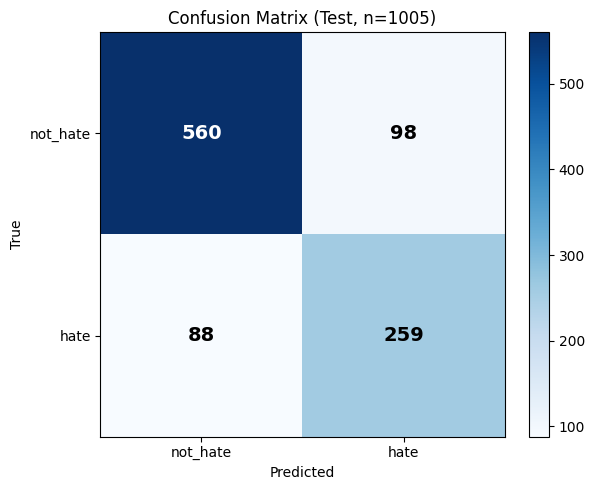


Classification report:
              precision    recall  f1-score   support

    not_hate     0.8642    0.8511    0.8576       658
        hate     0.7255    0.7464    0.7358       347

    accuracy                         0.8149      1005
   macro avg     0.7948    0.7987    0.7967      1005
weighted avg     0.8163    0.8149    0.8155      1005



In [11]:
cm_data = confusion_matrix(trues, preds)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_data, cmap="Blues")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["not_hate", "hate"]); ax.set_yticklabels(["not_hate", "hate"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix (Test, n={len(trues)})", fontsize=12)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_data[i, j]), ha="center", va="center",
                color="white" if cm_data[i, j] > cm_data.max()/2 else "black",
                fontsize=14, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

print("\nClassification report:")
print(classification_report(trues, preds, target_names=["not_hate", "hate"], digits=4))

In [12]:
from collections import Counter

# Group sampel per topik (utama, ambil first topic kalau multi)
df_meta["primary_topic"] = df_meta["topic"].apply(lambda t: str(t).split(",")[0].strip().lower() if pd.notna(t) else "unknown")

per_topic_top_tokens = {}
TOP_K = 5
SPECIAL = {"[CLS]", "[SEP]", "[PAD]", "[UNK]"}

for topic in df_meta["primary_topic"].unique():
    topic_idxs = df_meta[df_meta["primary_topic"] == topic]["idx"].values
    bag = Counter()
    for samp_idx in topic_idxs:
        pos = get_idx_position(samp_idx)
        toks = attr["ig_text"]["tokens"][int(samp_idx)]
        scores = attr["ig_text"]["token_l2"][pos]
        mask = attr["ig_text"]["att_mask"][pos]
        eligible = [(t, s) for t, s, m in zip(toks, scores, mask) if m and t not in SPECIAL]
        if not eligible: continue
        eligible.sort(key=lambda x: -x[1])
        for tok, _ in eligible[:TOP_K]:
            bag[tok.lower()] += 1
    per_topic_top_tokens[topic] = bag.most_common(15)

print(f"\n{'='*72}\nTOP-{TOP_K} TOKENS PER TOPIK (IG attribution)\n{'='*72}")
for topic, top in per_topic_top_tokens.items():
    n = len(df_meta[df_meta["primary_topic"] == topic])
    print(f"\n[{topic.upper()}] (n={n}):")
    for tok, ct in top[:10]:
        print(f"  {tok:30s} {ct:4d}")


TOP-5 TOKENS PER TOPIK (IG attribution)

[SOCIAL SUB-GROUPS] (n=500):
  group                           274
  sub                             168
  humor                            68
  social                           46
  seorang                          30
  ketika                           25
  [                                20
  ironi                            17
  sudah                            17
  menggambarkan                    16

[GENDER] (n=138):
  gender                          102
  [                                36
  humor                            22
  group                            15
  kontras                          10
  ketika                           10
  pria                              9
  seorang                           7
  publik                            6
  wanita                            5

[INDIVIDUAL] (n=118):
  individual                       86
  political                        44
  seorang                          18
  [          

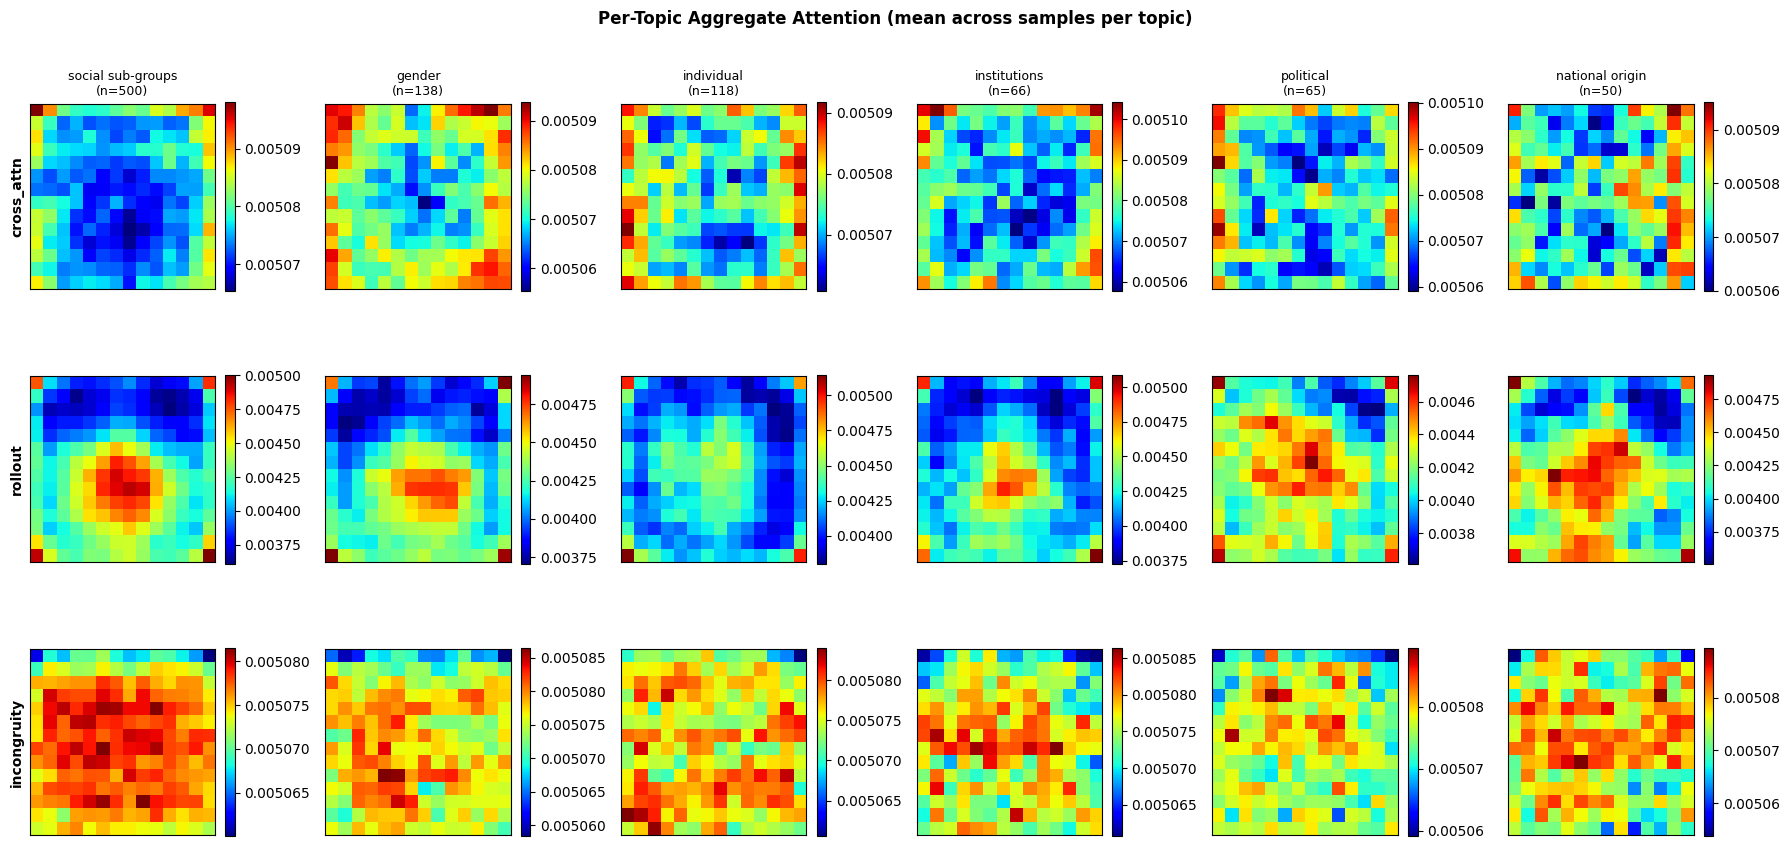

In [13]:
topics_to_show = df_meta["primary_topic"].value_counts().head(6).index.tolist()

fig, axes = plt.subplots(3, len(topics_to_show), figsize=(3*len(topics_to_show), 9))
if len(topics_to_show) == 1: axes = axes.reshape(3, 1)

method_names = ["cross_attn", "rollout", "incongruity"]
for col, topic in enumerate(topics_to_show):
    topic_idxs = df_meta[df_meta["primary_topic"] == topic]["idx"].values
    positions = [get_idx_position(i) for i in topic_idxs]
    n_topic = len(positions)
    for row, m in enumerate(method_names):
        if positions:
            avg_map = attr[m]["maps"][positions].mean(axis=0)
        else:
            avg_map = np.zeros((14,14))
        im = axes[row, col].imshow(avg_map, cmap="jet")
        if row == 0:
            axes[row, col].set_title(f"{topic}\n(n={n_topic})", fontsize=9)
        if col == 0:
            axes[row, col].set_ylabel(m, fontsize=10, fontweight="bold")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        plt.colorbar(im, ax=axes[row, col], fraction=0.046)

fig.suptitle("Per-Topic Aggregate Attention (mean across samples per topic)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "per_topic_attention.png", dpi=120, bbox_inches="tight")
plt.show()

In [14]:
print(f"\n{'='*72}\nERROR ANALYSIS - False Positives (FP)\n{'='*72}")
fp_samples = df_meta[df_meta["category"] == "FP"]
print(f"Total FP: {len(fp_samples)}  ({len(fp_samples)/len(df_meta)*100:.1f}% of test)")
print(f"\nFP per topic:")
print(fp_samples["primary_topic"].value_counts())

print(f"\nTop tokens yg paling sering top-K di FP cases:")
fp_tokens = Counter()
for _, s in fp_samples.iterrows():
    pos = get_idx_position(s["idx"])
    toks = attr["ig_text"]["tokens"][int(s["idx"])]
    scores = attr["ig_text"]["token_l2"][pos]
    mask = attr["ig_text"]["att_mask"][pos]
    eligible = [(t, sc) for t, sc, m in zip(toks, scores, mask) if m and t not in SPECIAL]
    eligible.sort(key=lambda x: -x[1])
    for tok, _ in eligible[:5]:
        fp_tokens[tok.lower()] += 1
for tok, ct in fp_tokens.most_common(15):
    print(f"  {tok:30s} {ct:4d}")

print(f"\n{'='*72}\nERROR ANALYSIS - False Negatives (FN)\n{'='*72}")
fn_samples = df_meta[df_meta["category"] == "FN"]
print(f"Total FN: {len(fn_samples)}  ({len(fn_samples)/len(df_meta)*100:.1f}% of test)")
print(f"\nFN per topic:")
print(fn_samples["primary_topic"].value_counts())

print(f"\nTop tokens yg paling sering top-K di FN cases:")
fn_tokens = Counter()
for _, s in fn_samples.iterrows():
    pos = get_idx_position(s["idx"])
    toks = attr["ig_text"]["tokens"][int(s["idx"])]
    scores = attr["ig_text"]["token_l2"][pos]
    mask = attr["ig_text"]["att_mask"][pos]
    eligible = [(t, sc) for t, sc, m in zip(toks, scores, mask) if m and t not in SPECIAL]
    eligible.sort(key=lambda x: -x[1])
    for tok, _ in eligible[:5]:
        fn_tokens[tok.lower()] += 1
for tok, ct in fn_tokens.most_common(15):
    print(f"  {tok:30s} {ct:4d}")


ERROR ANALYSIS - False Positives (FP)
Total FP: 98  (9.8% of test)

FP per topic:
primary_topic
social sub-groups    27
individual           23
gender               22
national origin       9
institutions          8
political             8
religion              1
Name: count, dtype: int64

Top tokens yg paling sering top-K di FP cases:
  [                                25
  gender                           21
  political                        20
  individual                       18
  group                            11
  institut                         10
  orig                             10
  ##ion                             8
  seorang                           8
  satir                             8
  perilaku                          7
  sub                               7
  national                          7
  humor                             5
  publik                            4

ERROR ANALYSIS - False Negatives (FN)
Total FN: 88  (8.8% of test)

FN per topic:
primary_

In [15]:
err_table = []
for topic in df_meta["primary_topic"].unique():
    sub = df_meta[df_meta["primary_topic"] == topic]
    n = len(sub)
    if n == 0: continue
    n_correct = (sub["pred"] == sub["true"]).sum()
    err_table.append({
        "topic":     topic,
        "n_samples": n,
        "accuracy":  n_correct / n,
        "n_FP":      ((sub["pred"] == 1) & (sub["true"] == 0)).sum(),
        "n_FN":      ((sub["pred"] == 0) & (sub["true"] == 1)).sum(),
        "n_TP":      ((sub["pred"] == 1) & (sub["true"] == 1)).sum(),
        "n_TN":      ((sub["pred"] == 0) & (sub["true"] == 0)).sum(),
    })
df_err = pd.DataFrame(err_table).sort_values("n_samples", ascending=False)
print(df_err.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
df_err.to_csv(OUTPUT_DIR / "error_per_topic.csv", index=False)

            topic  n_samples  accuracy  n_FP  n_FN  n_TP  n_TN
social sub-groups        500    0.8640    27    41    47   385
           gender        138    0.6884    22    21    18    77
       individual        118    0.7288    23     9    70    16
     institutions         66    0.7273     8    10    36    12
        political         65    0.8308     8     3    50     4
  national origin         50    0.7800     9     2    36     3
          unknown         49    1.0000     0     0     0    49
         religion         19    0.8421     1     2     2    14


In [16]:
summary_methods = {
    "Method": ["IG (text)", "Cross-Attention", "Attention Rollout", "Incongruity (NOVEL)"],
    "Domain": ["Text", "Image", "Image", "Image"],
    "Selectivity (top-10 share)": ["high (topic+content)", "5.2% (≈uniform)", "6.9% (1.35x)", "5.1% (≈uniform)"],
    "Class Differentiation":      ["yes (vocab beda)",     "no",               "no",            "yes (max diff=0.032)"],
    "Perturbation Faithful?":     ["YES (Δ -5%)",          "no",               "no",            "no"],
    "ROAR Faithful?":             ["YES (3 levels)",       "no (noise)",       "no (noise)",    "no (noise)"],
    "Paper Role":                 ["Komp 1: text attribution", "Baseline (uniform finding)", "Baseline (ViT bias finding)", "Komp 4: NOVEL architectural attribution"],
}
df_summary = pd.DataFrame(summary_methods)
print(df_summary.to_string(index=False))
df_summary.to_csv(OUTPUT_DIR / "xai_methods_summary.csv", index=False)

             Method Domain Selectivity (top-10 share) Class Differentiation Perturbation Faithful? ROAR Faithful?                              Paper Role
          IG (text)   Text       high (topic+content)      yes (vocab beda)            YES (Δ -5%) YES (3 levels)                Komp 1: text attribution
    Cross-Attention  Image            5.2% (≈uniform)                    no                     no     no (noise)              Baseline (uniform finding)
  Attention Rollout  Image               6.9% (1.35x)                    no                     no     no (noise)             Baseline (ViT bias finding)
Incongruity (NOVEL)  Image            5.1% (≈uniform)  yes (max diff=0.032)                     no     no (noise) Komp 4: NOVEL architectural attribution


In [17]:
final_summary = {
    "exp_id": CONFIG["exp_id"],
    "n_test_samples":  int(len(df_meta)),
    "n_case_studies":  len(selected_samples),
    "outcome_distribution": df_meta["category"].value_counts().to_dict(),
    "topic_error_rates": df_err.to_dict(orient="records"),
    "fp_top_tokens":  fp_tokens.most_common(15),
    "fn_top_tokens":  fn_tokens.most_common(15),
    "per_topic_top_tokens": {k: v for k, v in per_topic_top_tokens.items()},
    "case_studies": [
        {
            "idx":       int(s["idx"]),
            "category":  s["category"],
            "topic":     s["topic"],
            "pred":      int(s["pred"]),
            "true":      int(s["true"]),
            "prob":      float(s["prob"]),
            "figure":    f"case_{i+1:02d}_{s['category']}_idx{s['idx']}.png",
        }
        for i, s in enumerate(selected_samples)
    ],
}

with open(OUTPUT_DIR / "case_studies_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2, default=str)

print(f"\n{'='*72}\nFASE 2C (CASE STUDIES) DONE\n{'='*72}")
print(f"Total case studies      : {len(selected_samples)}")
print(f"Total figures saved     : {len(list(FIG_DIR.glob('*.png')))}")
print(f"Output dir              : {OUTPUT_DIR}")
print(f"\nKey artifacts:")
print(f"  - figures/             : {len(selected_samples)} per-sample case study + aggregate")
print(f"  - confusion_matrix.png : test set confusion matrix")
print(f"  - per_topic_attention.png : aggregate attention per topik")
print(f"  - error_per_topic.csv  : akurasi & FP/FN per topik")
print(f"  - xai_methods_summary.csv : ringkasan 4 metode XAI")
print(f"  - case_studies_summary.json : metadata semua case study")


FASE 2C (CASE STUDIES) DONE
Total case studies      : 10
Total figures saved     : 12
Output dir              : /kaggle/working/xai_2C_case_studies

Key artifacts:
  - figures/             : 10 per-sample case study + aggregate
  - confusion_matrix.png : test set confusion matrix
  - per_topic_attention.png : aggregate attention per topik
  - error_per_topic.csv  : akurasi & FP/FN per topik
  - xai_methods_summary.csv : ringkasan 4 metode XAI
  - case_studies_summary.json : metadata semua case study
